In [1]:
import warnings
warnings.filterwarnings('ignore')

import sys
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import graphviz as gr
from pathlib import Path
%matplotlib inline

In [2]:
cwd = Path.cwd()
project_root = cwd.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print("Done!")

Done!


In [3]:
corona_effect = pd.read_csv(project_root / 'data' / 'online_classroom.csv').query("format_blended==0")
corona_effect.head()

,gender,asian,black,hawaiian,hispanic,unknown,white,format_ol,format_blended,falsexam
0,0,0.0,0.0,0.0,0.0,0.0,1.0,0,0.0,63.29997
1,1,0.0,0.0,0.0,0.0,0.0,1.0,0,0.0,79.96000
4,1,0.0,0.0,0.0,0.0,0.0,1.0,1,0.0,83.30000
5,0,1.0,0.0,0.0,0.0,0.0,0.0,1,0.0,88.34996
7,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,90.00000


In [4]:
result = smf.ols('falsexam ~ format_ol', data=corona_effect).fit()
result.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,78.5475,1.113,70.563,0.000,76.353,80.742
format_ol,-4.9122,1.680,-2.925,0.004,-8.223,-1.601


In [5]:
corona_effect.groupby(by='format_ol')['falsexam'].mean()

format_ol
0    78.547485
1    73.635263
Name: falsexam, dtype: float64

In [6]:
X = corona_effect[['format_ol']].assign(intercept=1)
y = corona_effect['falsexam']

def regress(X, y):
    return np.linalg.inv(X.T.dot(X)).dot(X.T.dot(y))

In [7]:
beta = regress(X=X, y=y)
beta

array([-4.9122215 , 78.54748458])

In [8]:
kappa = corona_effect['falsexam'].cov(corona_effect['format_ol']) / corona_effect['format_ol'].var()
kappa

np.float64(-4.91222149822695)

In [9]:
e = y - X.dot(beta)
e

0     -15.247515
1       1.412515
4       9.664737
5      14.714697
7      11.452515
         ...    
316    13.102515
317     6.442515
319    -3.585263
320    -6.945263
321     9.664707
Length: 214, dtype: float64

In [10]:
np.dot(e, X)

array([-1.86162197e-12,  1.99662509e-12])

In [22]:
wage_df = pd.read_csv(project_root / 'data' / 'wage.csv')
wage_df.head()

,wage,hours,lhwage,IQ,educ,exper,tenure,age,married,black,south,urban,sibs,brthord,meduc,feduc
0,769,40,2.956212,93,12,11,2,31,1,0,0,1,1,2.0,8.0,8.0
1,808,50,2.782539,119,18,11,16,37,1,0,0,1,1,NaN,14.0,14.0
2,825,40,3.026504,108,14,11,9,33,1,0,0,1,1,2.0,14.0,14.0
3,650,40,2.788093,96,12,13,7,32,1,0,0,1,4,3.0,12.0,12.0
4,562,40,2.642622,74,11,14,5,34,1,0,0,1,10,6.0,6.0,11.0


In [23]:
wage_df.shape

(935, 16)

In [24]:
wage_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 935 entries, 0 to 934
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   wage     935 non-null    int64  
 1   hours    935 non-null    int64  
 2   lhwage   935 non-null    float64
 3   IQ       935 non-null    int64  
 4   educ     935 non-null    int64  
 5   exper    935 non-null    int64  
 6   tenure   935 non-null    int64  
 7   age      935 non-null    int64  
 8   married  935 non-null    int64  
 9   black    935 non-null    int64  
 10  south    935 non-null    int64  
 11  urban    935 non-null    int64  
 12  sibs     935 non-null    int64  
 13  brthord  852 non-null    float64
 14  meduc    857 non-null    float64
 15  feduc    741 non-null    float64
dtypes: float64(4), int64(12)
memory usage: 117.0 KB


In [26]:
model_1 = smf.ols("np.log(hwage) ~ educ", data=wage_df.assign(hwage=wage_df['wage'].divide(wage_df['hours']))).fit()
model_1.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,2.2954,0.089,25.754,0.000,2.121,2.470
educ,0.0529,0.007,8.107,0.000,0.040,0.066


In [27]:
from matplotlib import pyplot as plt
from matplotlib import style

style.use("fivethirtyeight")

In [29]:
model_1.params['educ']

np.float64(0.05294724081876345)

In [30]:
model_1.params['Intercept']

np.float64(2.2954231510925496)

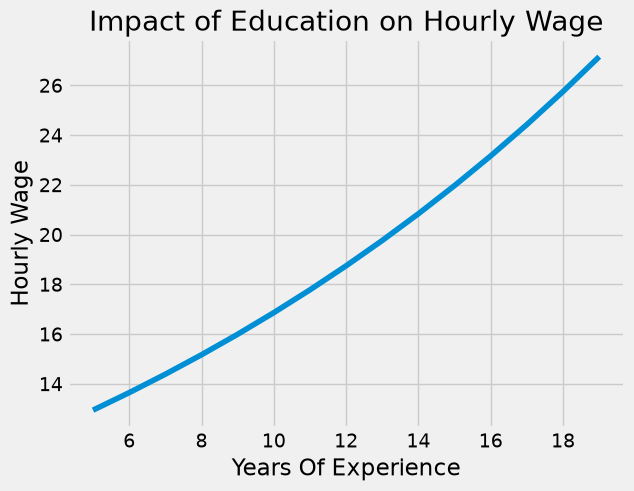

In [32]:
x = np.arange(5, 20)
plt.plot(x, np.exp(model_1.params['Intercept'] + model_1.params['educ'] * x))
plt.xlabel("Years Of Experience")
plt.ylabel("Hourly Wage")
plt.title("Impact of Education on Hourly Wage")
plt.show()

In [33]:
wage_df

,wage,hours,lhwage,IQ,educ,exper,tenure,age,married,black,south,urban,sibs,brthord,meduc,feduc
0,769,40,2.956212,93,12,11,2,31,1,0,0,1,1,2.0,8.0,8.0
1,808,50,2.782539,119,18,11,16,37,1,0,0,1,1,NaN,14.0,14.0
2,825,40,3.026504,108,14,11,9,33,1,0,0,1,1,2.0,14.0,14.0
3,650,40,2.788093,96,12,13,7,32,1,0,0,1,4,3.0,12.0,12.0
4,562,40,2.642622,74,11,14,5,34,1,0,0,1,10,6.0,6.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
930,520,40,2.564949,79,16,6,1,30,1,1,1,0,0,1.0,11.0,NaN
931,1202,40,3.402863,102,13,10,3,31,1,0,1,1,7,7.0,8.0,6.0
932,538,45,2.481196,77,12,12,10,28,1,1,1,0,9,NaN,7.0,NaN
933,873,44,2.987746,109,12,12,12,28,1,0,1,0,1,1.0,NaN,11.0


In [34]:
wage_df.columns

Index(['wage', 'hours', 'lhwage', 'IQ', 'educ', 'exper', 'tenure', 'age',
       'married', 'black', 'south', 'urban', 'sibs', 'brthord', 'meduc',
       'feduc'],
      dtype='str')

In [44]:
controls = ['IQ', 'exper', 'tenure', 'age', 'married', 'black',
            'south', 'urban', 'sibs', 'brthord', 'meduc', 'feduc']

df = wage_df.dropna()
X = df[controls].assign(intercept=1)
t = df['educ']
y = df['lhwage']

beta_aux = regress(X=X, y=t)
t_tilda = t - X.dot(beta_aux)

kappa = t_tilda.cov(y) / t_tilda.var()
kappa

np.float64(0.041147191010059404)

This coefficient we’ve just estimated tells us that, for people with the same IQ, experience, tenure, age and so on, we should expect an additional year of education to be associated with a 4.11% increase in hourly wage. This confirms our suspicion that the first simple model with only educ was biased. It also confirms that this bias was overestimating the impact of education. Once we controlled for other factors, the estimated impact of education fell.

In [45]:
model_2 = smf.ols('lhwage ~ educ +' + '+'.join(controls), data=df).fit()
model_2.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,1.1156,0.232,4.802,0.000,0.659,1.572
educ,0.0411,0.010,4.075,0.000,0.021,0.061
IQ,0.0038,0.001,2.794,0.005,0.001,0.006
exper,0.0153,0.005,3.032,0.003,0.005,0.025
tenure,0.0094,0.003,2.836,0.005,0.003,0.016
age,0.0086,0.006,1.364,0.173,-0.004,0.021
married,0.1795,0.053,3.415,0.001,0.076,0.283
black,-0.0801,0.063,-1.263,0.207,-0.205,0.044
south,-0.0397,0.035,-1.129,0.259,-0.109,0.029
urban,0.1926,0.036,5.418,0.000,0.123,0.262
